In [1]:
!wget https://raw.githubusercontent.com/HARAJIT05/DATASETS-DATASCIENCE/main/fastfood.csv


--2026-11-24 19:27:00--  https://raw.githubusercontent.com/HARAJIT05/DATASETS-DATASCIENCE/main/fastfood.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 43604 (43K) [text/plain]
Saving to: ‘fastfood.csv’

fastfood.csv        100%[===================>]  42.58K  --.-KB/s    in 0.03s   

2026-11-24 19:27:00 (1.65 MB/s) - ‘fastfood.csv’ saved [43604/43604]



In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv('fastfood.csv')

# Display the columns and data types
df.info()

# Display the first few rows
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    object 
 1   item         515 non-null    object 
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    int64  
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    float64
 13  vit_a        301 non-null    float64
 14  vit_c        305 non-null    float64
 15  calcium      305 non-null    float64
 16  salad        515 non-null    object 
dtypes: float64(7), int64(7), object(3)
memory usage: 68.5+ KB


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


### Question 1: Which restaurant has the highest number of food items in the dataset?

In [3]:
# Count items per restaurant
item_counts = df['restaurant'].value_counts()
display(item_counts.to_frame(name='Number of Items'))

highest_restaurant = item_counts.idxmax()
highest_count = item_counts.max()
print(f"\nRestaurant with the highest number of food items: {highest_restaurant} ({highest_count} items)")

,Number of Items
restaurant,
Taco Bell,115
Subway,96
Burger King,70
Mcdonalds,57
Arbys,55
Sonic,53
Dairy Queen,42
Chick Fil-A,27



Restaurant with the highest number of food items: Taco Bell (115 items)


### Question 2: Which food items have the highest number of calories? Find the top 10 items.

In [4]:
# Find top 10 food items by calories
top_10_calories = df[['restaurant', 'item', 'calories']].sort_values(by='calories', ascending=False).head(10)
display(top_10_calories)

,restaurant,item,calories
39,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430
44,Mcdonalds,40 piece Chicken McNuggets,1770
47,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,1600
192,Burger King,American Brewhouse King,1550
38,Mcdonalds,12 piece Buttermilk Crispy Chicken Tenders,1510
115,Sonic,Garlic Parmesan Dunked Ultimate Chicken Sandwich,1350
98,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280
270,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,1260
211,Burger King,Rodeo King,1250
205,Burger King,Farmhouse King,1220


### Question 3: What is the average calorie count of food items for each restaurant?

In [5]:
# Calculate average calories per restaurant
avg_calories = df.groupby('restaurant')['calories'].mean().sort_values(ascending=False).to_frame(name='Average Calories')
display(avg_calories)

,Average Calories
restaurant,
Mcdonalds,640.350877
Sonic,631.698113
Burger King,608.571429
Arbys,532.727273
Dairy Queen,520.238095
Subway,503.020833
Taco Bell,443.652174
Chick Fil-A,384.444444


### Question 4: Which restaurant offers food items with the highest average protein content?

In [6]:
# Calculate average protein content per restaurant
avg_protein = df.groupby('restaurant')['protein'].mean().sort_values(ascending=False).to_frame(name='Average Protein (g)')
display(avg_protein)

highest_protein_restaurant = avg_protein.index[0]
highest_protein_val = avg_protein.iloc[0, 0]
print(f"\n{highest_protein_restaurant} offers food items with the highest average protein content ({highest_protein_val:.2f}g).")

,Average Protein (g)
restaurant,
Mcdonalds,40.298246
Chick Fil-A,31.703704
Subway,30.312500
Burger King,30.014493
Arbys,29.254545
Sonic,29.188679
Dairy Queen,24.833333
Taco Bell,17.417391



Mcdonalds offers food items with the highest average protein content (40.30g).


### Question 5: Which restaurant has the highest average amount of total fat, and which restaurant has the lowest?

In [7]:
# Calculate average total fat per restaurant
avg_fat = df.groupby('restaurant')['total_fat'].mean().sort_values(ascending=False).to_frame(name='Average Total Fat (g)')
display(avg_fat)

highest_fat_restaurant = avg_fat.index[0]
highest_fat_val = avg_fat.iloc[0, 0]
lowest_fat_restaurant = avg_fat.index[-1]
lowest_fat_val = avg_fat.iloc[-1, 0]

print(f"\nHighest average total fat: {highest_fat_restaurant} ({highest_fat_val:.2f}g)")
print(f"Lowest average total fat: {lowest_fat_restaurant} ({lowest_fat_val:.2f}g)")

,Average Total Fat (g)
restaurant,
Sonic,37.641509
Burger King,36.814286
Mcdonalds,31.807018
Dairy Queen,28.857143
Arbys,26.981818
Taco Bell,20.895652
Subway,18.479167
Chick Fil-A,16.148148



Highest average total fat: Sonic (37.64g)
Lowest average total fat: Chick Fil-A (16.15g)


### Question 6: Which food items contain the highest amount of sugar, and how many calories do those items contain?

In [8]:
# Top 10 food items with the highest amount of sugar and their calorie values
top_sugar_items = df[['restaurant', 'item', 'sugar', 'calories']].sort_values(by='sugar', ascending=False).head(10)
display(top_sugar_items)

,restaurant,item,sugar,calories
47,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,87,1600
46,Mcdonalds,6 piece Sweet N' Spicy Honey BBQ Glazed Tenders,52,960
229,Burger King,"Chicken, Apple & Cranberry Salad w/ Crispy Chi...",37,700
351,Subway,Footlong Sweet Onion Chicken Teriyaki,36,760
45,Mcdonalds,4 piece Sweet N' Spicy Honey BBQ Glazed Tenders,35,640
228,Burger King,"Chicken, Apple & Cranberry Salad w/ Grilled Ch...",34,560
280,Dairy Queen,Large Cheese Curds,30,1050
326,Subway,Footlong Corned Beef Reuben,24,940
332,Subway,Footlong Meatball Marinara,24,960
138,Arbys,Arby-Q Sandwich,23,400


### Question 7: How does the type of food item (salad or other) affect its average calories, fat, carbohydrates, and protein?

In [9]:
# Compare nutritional averages between Salad and Other food types
salad_comparison = df.groupby('salad')[['calories', 'total_fat', 'total_carb', 'protein']].mean()
display(salad_comparison)

,calories,total_fat,total_carb,protein
salad,,,,
Other,530.912621,26.590291,45.664078,27.891051


### Question 8: Which restaurant offers the best combination of low calories and high protein?

In [10]:
# We can define a metric: Protein-to-Calorie ratio (higher is better for low-calorie high-protein options)
df_ratio = df.copy()
df_ratio['protein_to_calorie_ratio'] = df_ratio['protein'] / df_ratio['calories']

# Group by restaurant and find the mean ratio
best_ratio_restaurant = df_ratio.groupby('restaurant')['protein_to_calorie_ratio'].mean().sort_values(ascending=False).to_frame(name='Avg Protein-to-Calorie Ratio')
display(best_ratio_restaurant)

print("Note: A higher protein-to-calorie ratio indicates a better balance of high protein relative to its calorie load.")

,Avg Protein-to-Calorie Ratio
restaurant,
Chick Fil-A,0.095789
Subway,0.065871
Mcdonalds,0.063161
Arbys,0.056228
Sonic,0.052450
Dairy Queen,0.050710
Burger King,0.048592
Taco Bell,0.040759


Note: A higher protein-to-calorie ratio indicates a better balance of high protein relative to its calorie load.


### Question 9: Can you identify the 10 least healthy food items by creating a Health Risk Score?

In [11]:
# We will scale the indicators to a 0-1 range to weigh them equally, then sum them up for the score.
# Formula: Score = scaled_calories + scaled_total_fat + scaled_sat_fat + scaled_trans_fat + scaled_cholesterol + scaled_sodium
risk_cols = ['calories', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium']
df_scaled = df.copy()

for col in risk_cols:
    df_scaled[f'scaled_{col}'] = (df_scaled[col] - df_scaled[col].min()) / (df_scaled[col].max() - df_scaled[col].min())

# Sum up scaled values to get Health Risk Score
df_scaled['health_risk_score'] = df_scaled[[f'scaled_{col}' for col in risk_cols]].sum(axis=1)

least_healthy = df_scaled[['restaurant', 'item', 'health_risk_score'] + risk_cols].sort_values(by='health_risk_score', ascending=False).head(10)
display(least_healthy)

,restaurant,item,health_risk_score,calories,total_fat,sat_fat,trans_fat,cholesterol,sodium
192,Burger King,American Brewhouse King,4.826081,1550,126,47.0,8.0,805,1820
39,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,4.350700,2430,141,24.0,2.0,475,6080
98,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),3.030525,1280,92,36.0,4.0,260,1630
101,Sonic,Super Sonic Double Cheeseburger W/ Mayo,2.890844,1220,87,34.0,4.0,245,1520
44,Mcdonalds,40 piece Chicken McNuggets,2.850119,1770,107,18.0,0.5,295,3370
211,Burger King,Rodeo King,2.846528,1250,82,31.0,3.5,230,2270
205,Burger King,Farmhouse King,2.787727,1220,80,28.0,3.0,335,2050
102,Sonic,Super Sonic Jalapeno Double Cheeseburger,2.744390,1120,76,32.0,4.0,235,1690
100,Sonic,Super Sonic Double Cheeseburger W/ Ketchup,2.736998,1130,76,32.0,4.0,235,1620
99,Sonic,Super Sonic Double Cheeseburger W/ Mustard,2.721307,1120,76,32.0,4.0,235,1550


### Question 10: Can you compare the nutritional profiles of all restaurants and determine which restaurant provides the healthiest overall menu?

In [12]:
# Define a Healthiness Scoring System:
# Standardize metrics so we can aggregate them.
# Positive contributors (Higher is healthier): fiber, protein, vit_a, vit_c, calcium
# Negative contributors (Lower is healthier): calories, total_fat, sugar, sodium
# We fill missing vitamins/fiber values with 0 for conservative estimation

health_df = df.copy()
health_df[['fiber', 'vit_a', 'vit_c', 'calcium', 'protein']] = health_df[['fiber', 'vit_a', 'vit_c', 'calcium', 'protein']].fillna(0)

pos_cols = ['fiber', 'protein', 'vit_a', 'vit_c', 'calcium']
neg_cols = ['calories', 'total_fat', 'sugar', 'sodium']

# Scale each feature
for col in pos_cols + neg_cols:
    health_df[f'norm_{col}'] = (health_df[col] - health_df[col].min()) / (health_df[col].max() - health_df[col].min())

# Calculate Menu Health Score per item
health_df['item_health_score'] = health_df[[f'norm_{col}' for col in pos_cols]].sum(axis=1) - health_df[[f'norm_{col}' for col in neg_cols]].sum(axis=1)

# Group by restaurant and find the mean health score
restaurant_health_rank = health_df.groupby('restaurant')['item_health_score'].mean().sort_values(ascending=False).to_frame(name='Overall Menu Health Score')
display(restaurant_health_rank)

,Overall Menu Health Score
restaurant,
Subway,0.258283
Taco Bell,-0.064777
Chick Fil-A,-0.080737
Mcdonalds,-0.134198
Dairy Queen,-0.284105
Arbys,-0.353301
Sonic,-0.398716
Burger King,-0.519442


## Data Visualizations
Let's visualize the results of our analysis using `matplotlib` and `seaborn` to make the insights easier to digest.

/tmp/ipykernel_945/641481563.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=item_counts.values, y=item_counts.index, ax=axes[0, 0], palette="viridis")
/tmp/ipykernel_945/641481563.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_calories['Average Calories'], y=avg_calories.index, ax=axes[0, 1], palette="magma")
/tmp/ipykernel_945/641481563.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_protein['Average Protein (g)'], y=avg_protein.index, ax=axes[1, 0], palette="crest")
/tmp/ipykernel_945/641481563.py:26: FutureWa

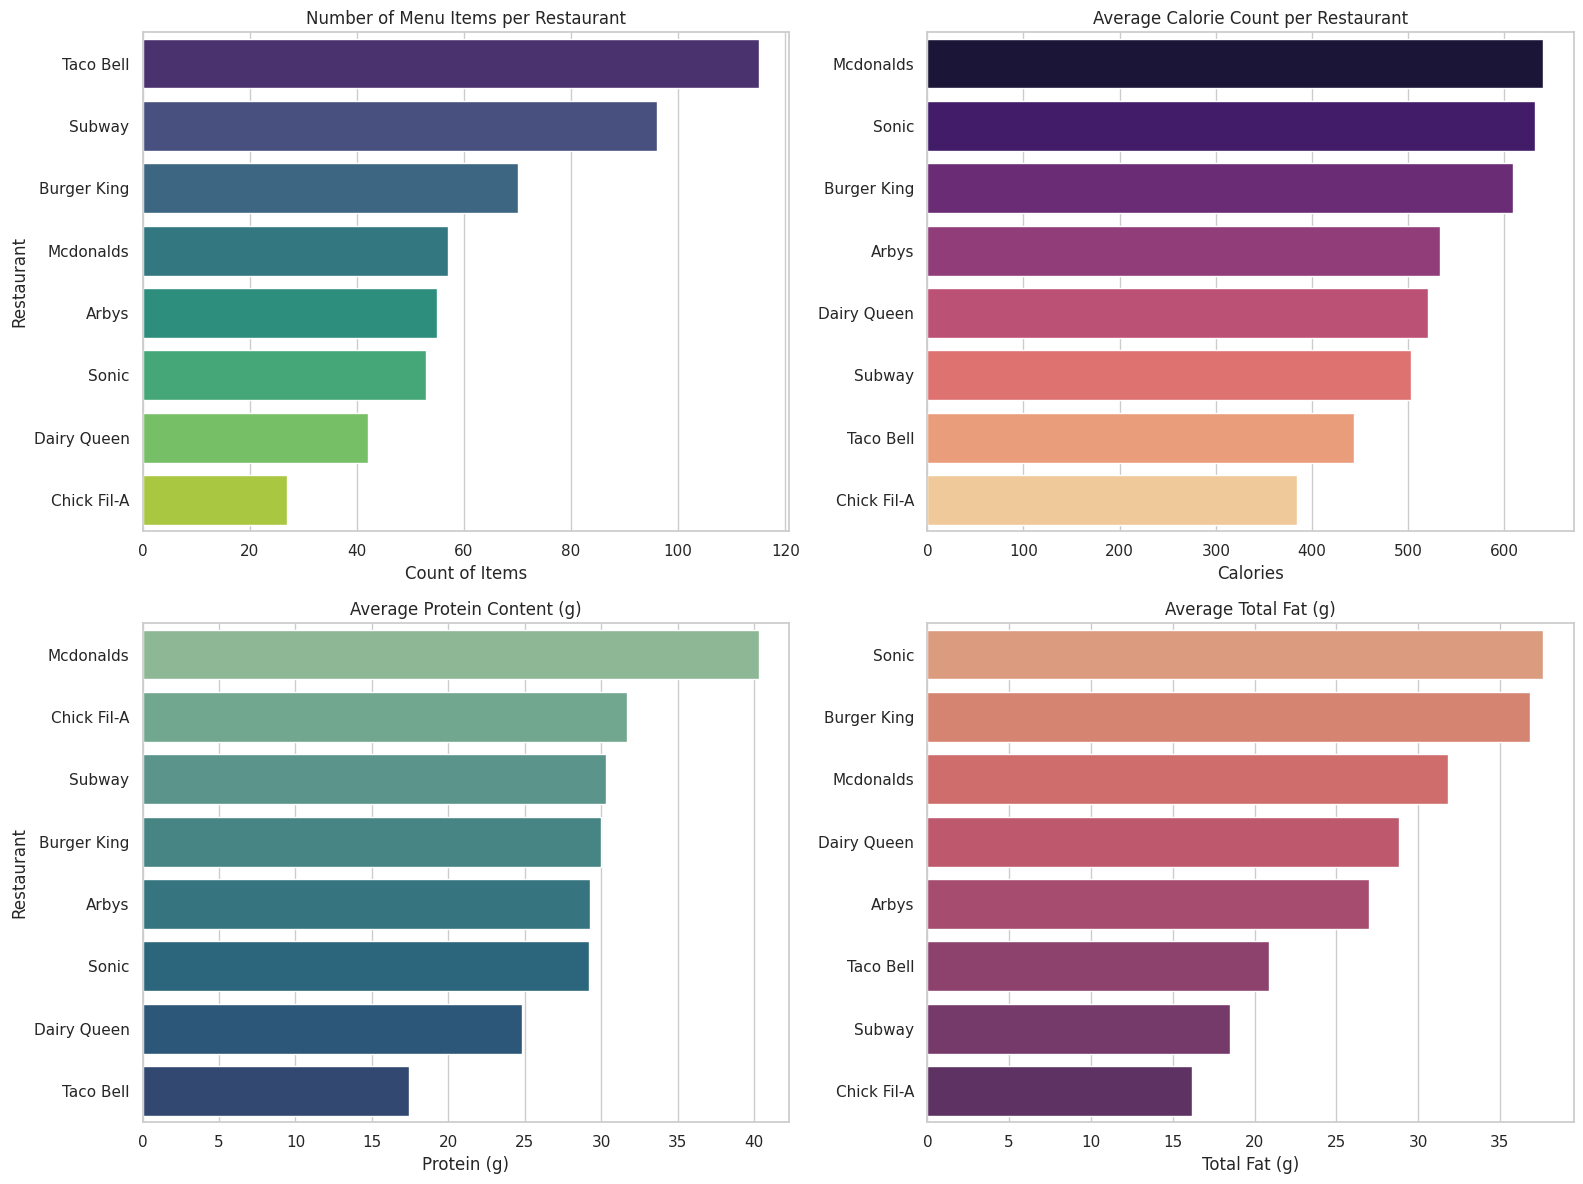

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Number of Food Items per Restaurant
sns.barplot(x=item_counts.values, y=item_counts.index, ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Number of Menu Items per Restaurant")
axes[0, 0].set_xlabel("Count of Items")
axes[0, 0].set_ylabel("Restaurant")

# 2. Average Calories per Restaurant
sns.barplot(x=avg_calories['Average Calories'], y=avg_calories.index, ax=axes[0, 1], palette="magma")
axes[0, 1].set_title("Average Calorie Count per Restaurant")
axes[0, 1].set_xlabel("Calories")
axes[0, 1].set_ylabel("")

# 3. Average Protein Content per Restaurant
sns.barplot(x=avg_protein['Average Protein (g)'], y=avg_protein.index, ax=axes[1, 0], palette="crest")
axes[1, 0].set_title("Average Protein Content (g)")
axes[1, 0].set_xlabel("Protein (g)")
axes[1, 0].set_ylabel("Restaurant")

# 4. Average Total Fat per Restaurant
sns.barplot(x=avg_fat['Average Total Fat (g)'], y=avg_fat.index, ax=axes[1, 1], palette="flare")
axes[1, 1].set_title("Average Total Fat (g)")
axes[1, 1].set_xlabel("Total Fat (g)")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

/tmp/ipykernel_945/3340645206.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


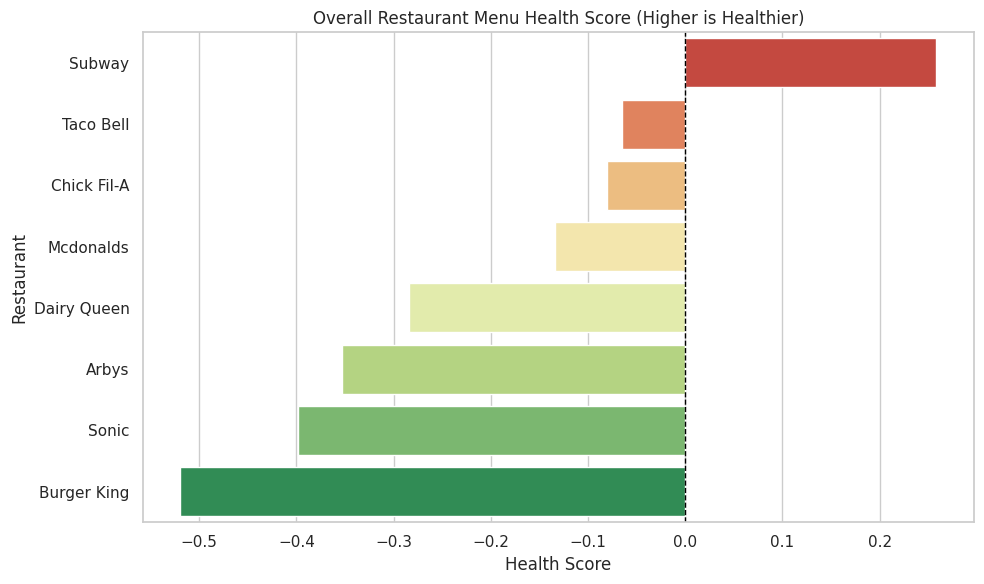

In [14]:
# 5. Visualize Overall Menu Health Scores
plt.figure(figsize=(10, 6))
sns.barplot(
    x=restaurant_health_rank['Overall Menu Health Score'],
    y=restaurant_health_rank.index,
    palette="RdYlGn"
)
plt.title("Overall Restaurant Menu Health Score (Higher is Healthier)")
plt.xlabel("Health Score")
plt.ylabel("Restaurant")
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()